# NASA C-MAPSS FD001: Data Exploration and RUL Baseline

## Objective

Explore the FD001 turbofan sensor data, create capped remaining-useful-life labels, and evaluate a simple 14-sensor Ridge baseline. This notebook is exploratory; the final comparison uses a separate training-only preprocessing protocol.

## Sensor selection

The baseline uses 14 sensors: sensor_2, sensor_3, sensor_4, sensor_7, sensor_8, sensor_9, sensor_11, sensor_12, sensor_13, sensor_14, sensor_15, sensor_17, sensor_20, and sensor_21. Sensor_6 is excluded as near-constant; it has two distinct values rather than being exactly constant.

## Protocol

Training RUL is calculated per engine and capped at 125. The baseline uses 30-cycle windows and the final cycle of each window; test evaluation reports both clipped and raw official RUL. Windows are split engine-wise into 80% training and 20% validation using split seed 42.

## Limitation

The scaler is fitted before the engine split, so validation-engine feature values influence preprocessing. Treat these results as exploratory; they are not used in the final comparison.

In [1]:
from pathlib import Path

# Walk up from the current folder until we find the dataset
cwd = Path.cwd()
print("Current working directory:", cwd)

PROJECT_ROOT = None
for folder in [cwd, *cwd.parents]:
    if (folder / "data" / "raw" / "train_FD001.txt").exists():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    print("train_FD001.txt not found in cwd or any parent.")
    print("Contents of cwd:", [p.name for p in cwd.iterdir()])
else:
    print("Project root:", PROJECT_ROOT)
    print("Raw files:", sorted(p.name for p in (PROJECT_ROOT / "data" / "raw").iterdir()))

Current working directory: C:\Users\samya\Desktop\mini_project
Project root: C:\Users\samya\Desktop\mini_project
Raw files: ['RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'readme.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']


In [2]:
import pandas as pd

DATA_DIR = PROJECT_ROOT / "data" / "raw"

columns = (
    ["unit_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=columns)
test_df  = pd.read_csv(DATA_DIR / "test_FD001.txt",  sep=r"\s+", header=None, names=columns)
rul_df   = pd.read_csv(DATA_DIR / "RUL_FD001.txt",   sep=r"\s+", header=None, names=["RUL"])

print("train", train_df.shape, "| engines:", train_df["unit_id"].nunique())
print("test ", test_df.shape,  "| engines:", test_df["unit_id"].nunique())
print("RUL  ", rul_df.shape)
print("NaNs:", train_df.isna().sum().sum(), test_df.isna().sum().sum())

train (20631, 26) | engines: 100
test  (13096, 26) | engines: 100
RUL   (100, 1)
NaNs: 0 0


In [3]:
# Cycles each training engine ran before failure
life = train_df.groupby("unit_id")["cycle"].max()
print("Train lifetimes:\n", life.describe())

# Cycles observed per test engine (sequences are cut off before failure)
test_len = test_df.groupby("unit_id")["cycle"].max()
print("\nTest observed lengths:\n", test_len.describe())

print("\nTrue RUL at test cutoff:\n", rul_df["RUL"].describe())

Train lifetimes:
 count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

Test observed lengths:
 count    100.000000
mean     130.960000
std       53.593479
min       31.000000
25%       88.750000
50%      133.500000
75%      164.250000
max      303.000000
Name: cycle, dtype: float64

True RUL at test cutoff:
 count    100.00000
mean      75.52000
std       41.76497
min        7.00000
25%       32.75000
50%       86.00000
75%      112.25000
max      145.00000
Name: RUL, dtype: float64


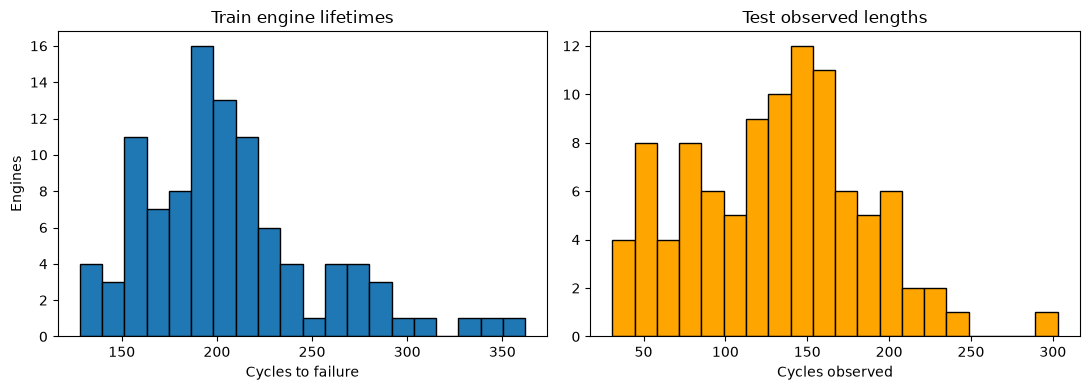

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(life, bins=20, edgecolor="black")
ax[0].set(title="Train engine lifetimes", xlabel="Cycles to failure", ylabel="Engines")
ax[1].hist(test_len, bins=20, edgecolor="black", color="orange")
ax[1].set(title="Test observed lengths", xlabel="Cycles observed")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "engine_lifetimes.png", dpi=150)
plt.show()

In [5]:
sensor_cols = [c for c in train_df.columns if c.startswith("sensor_")]
setting_cols = [c for c in train_df.columns if c.startswith("setting_")]

stats = train_df[setting_cols + sensor_cols].agg(["std", "nunique"]).T
print(stats.sort_values("std"))

                    std  nunique
sensor_1   0.000000e+00      1.0
setting_3  0.000000e+00      1.0
sensor_10  0.000000e+00      1.0
sensor_19  0.000000e+00      1.0
sensor_18  0.000000e+00      1.0
sensor_16  3.469531e-18      1.0
sensor_5   5.329200e-15      1.0
setting_2  2.930621e-04     13.0
sensor_6   1.388985e-03      2.0
setting_1  2.187313e-03    158.0
sensor_15  3.750504e-02   1918.0
sensor_8   7.098548e-02     53.0
sensor_13  7.191892e-02     56.0
sensor_21  1.082509e-01   4745.0
sensor_20  1.807464e-01    120.0
sensor_11  2.670874e-01    159.0
sensor_2   5.000533e-01    310.0
sensor_12  7.375534e-01    427.0
sensor_7   8.850923e-01    513.0
sensor_17  1.548763e+00     13.0
sensor_3   6.131150e+00   3012.0
sensor_4   9.000605e+00   4051.0
sensor_14  1.907618e+01   6078.0
sensor_9   2.208288e+01   6403.0


14 ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


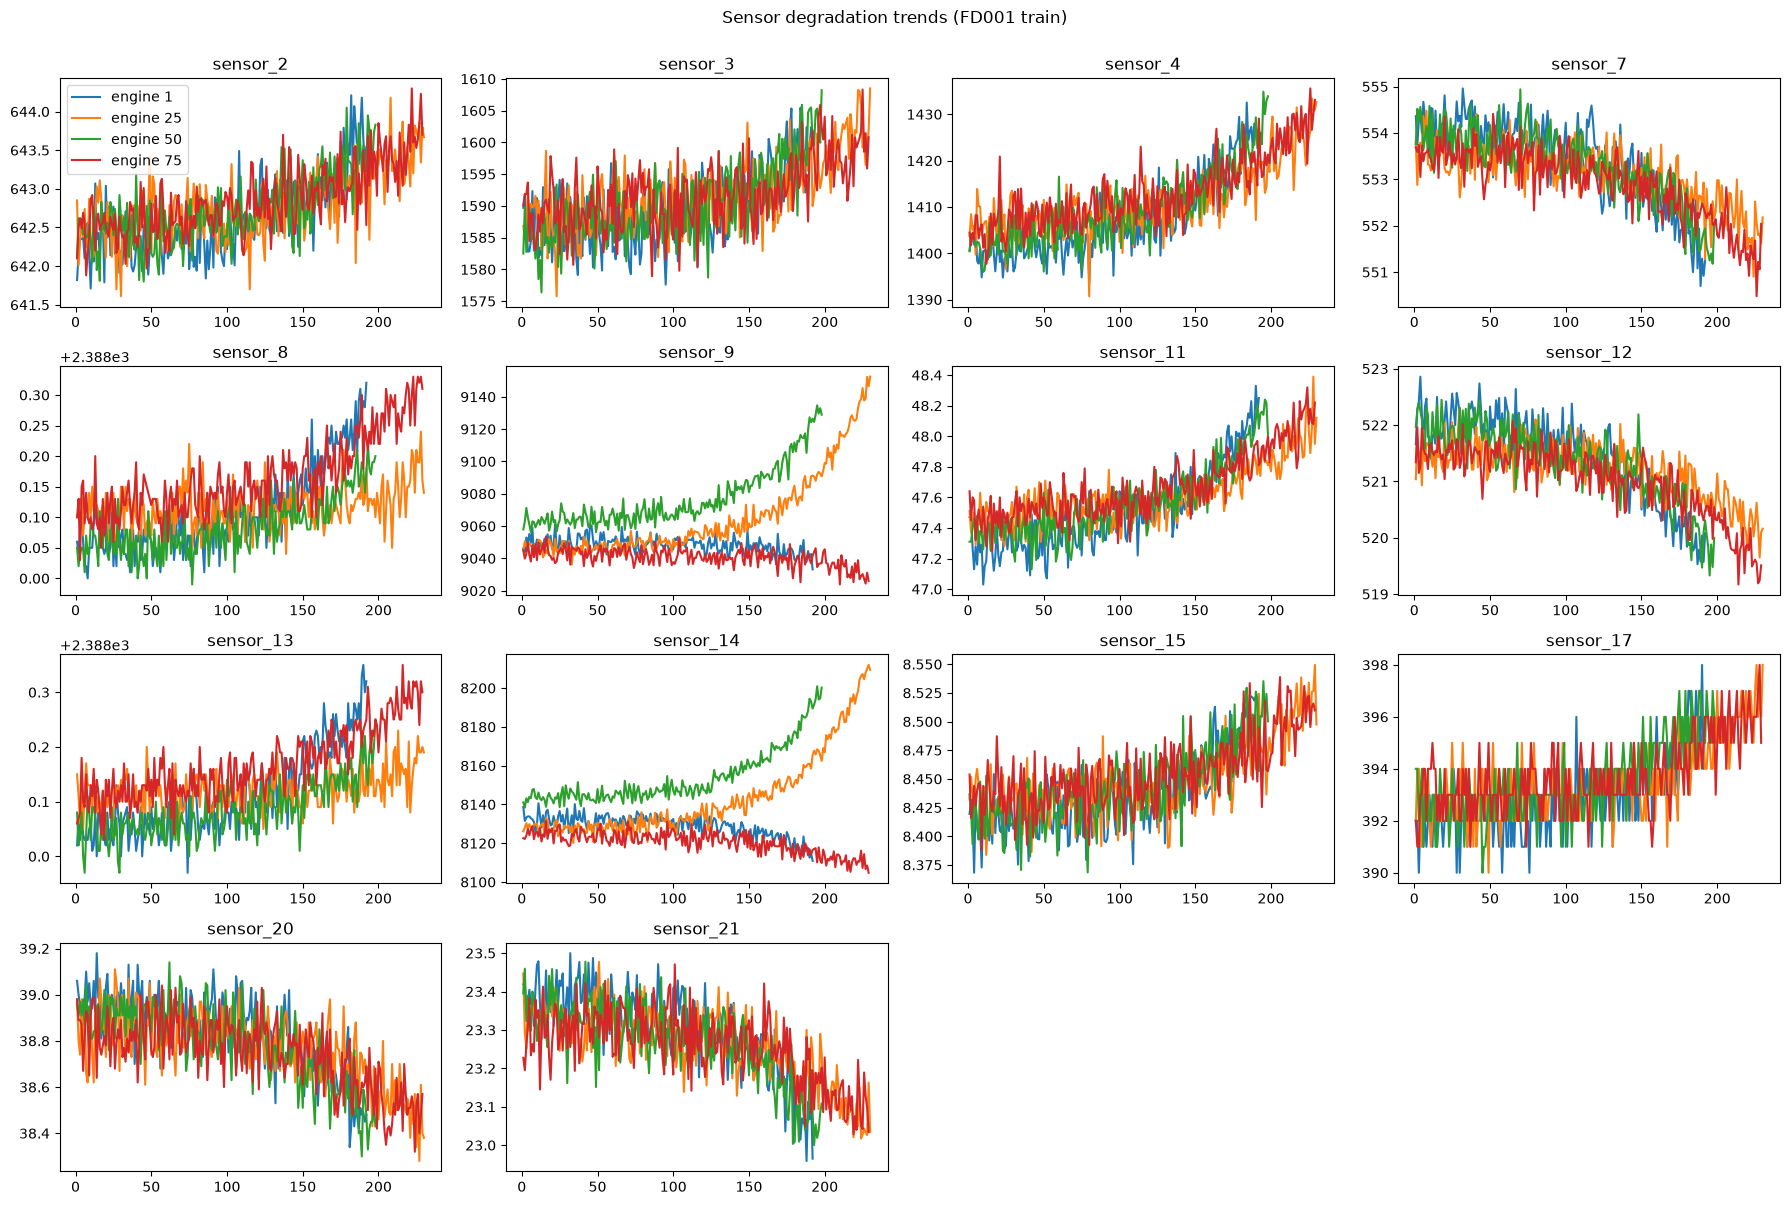

In [6]:
drop_cols = ["sensor_1", "sensor_5", "sensor_6", "sensor_10",
             "sensor_16", "sensor_18", "sensor_19",
             "setting_1", "setting_2", "setting_3"]
feature_cols = [c for c in sensor_cols if c not in drop_cols]
print(len(feature_cols), feature_cols)

# Plot each kept sensor vs cycle for 4 engines
engines = [1, 25, 50, 75]
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for ax, s in zip(axes.flat, feature_cols):
    for e in engines:
        d = train_df[train_df["unit_id"] == e]
        ax.plot(d["cycle"], d[s], label=f"engine {e}")
    ax.set_title(s)
for ax in axes.flat[len(feature_cols):]:
    ax.axis("off")          # hide the 2 unused panels
axes.flat[0].legend()
fig.suptitle("Sensor degradation trends (FD001 train)", y=1.0)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "sensor_trends.png", dpi=150)
plt.show()

   unit_id  cycle  RUL  RUL_clipped
0        1      1  191          125
1        1      2  190          125
2        1      3  189          125
3        1      4  188          125
4        1      5  187          125
     cycle  RUL  RUL_clipped
189    190    2            2
190    191    1            1
191    192    0            0

Test engines with RUL > 125: 11
   unit_id  cycle  RUL  RUL_clipped
0        1     31  112          112
1        2     49   98           98
2        3    126   69           69
3        4    106   82           82
4        5     98   91           91


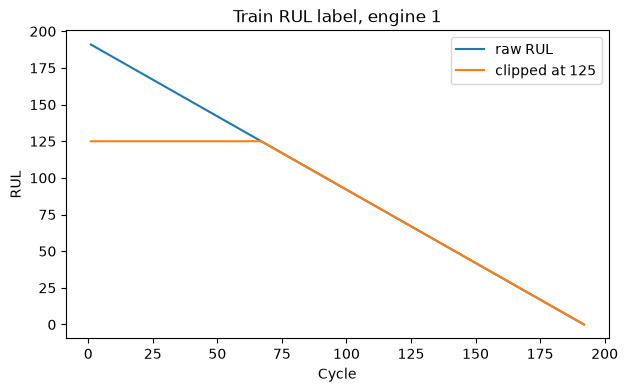

In [7]:
RUL_CAP = 125

# TRAIN: every engine runs to failure, so RUL = last cycle - current cycle
max_cycle = train_df.groupby("unit_id")["cycle"].transform("max")
train_df["RUL"] = max_cycle - train_df["cycle"]
train_df["RUL_clipped"] = train_df["RUL"].clip(upper=RUL_CAP)

# TEST: sequences stop early. rul_df gives the true RUL at each engine's LAST cycle.
# Engine ids are 1..100, in the same order as the rows of rul_df.
test_last = test_df.groupby("unit_id")["cycle"].max().reset_index()
test_last["RUL"] = rul_df["RUL"].values
test_last["RUL_clipped"] = test_last["RUL"].clip(upper=RUL_CAP)

print(train_df[["unit_id", "cycle", "RUL", "RUL_clipped"]].head())
print(train_df[train_df["unit_id"] == 1][["cycle", "RUL", "RUL_clipped"]].tail(3))
print("\nTest engines with RUL > 125:", (test_last["RUL"] > RUL_CAP).sum())
print(test_last.head())

# Raw vs clipped RUL for engine 1
d = train_df[train_df["unit_id"] == 1]
plt.figure(figsize=(7, 4))
plt.plot(d["cycle"], d["RUL"], label="raw RUL")
plt.plot(d["cycle"], d["RUL_clipped"], label="clipped at 125")
plt.xlabel("Cycle"); plt.ylabel("RUL"); plt.legend()
plt.title("Train RUL label, engine 1")
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "rul_clipping.png", dpi=150)
plt.show()

In [8]:
import numpy as np
import joblib
from sklearn.preprocessing import MinMaxScaler

WINDOW = 30

# 1. Scale: fit on TRAIN only, then apply the same scaler to test
scaler = MinMaxScaler()
train_scaled = train_df.copy()
test_scaled = test_df.copy()
train_scaled[feature_cols] = scaler.fit_transform(train_df[feature_cols])
test_scaled[feature_cols] = scaler.transform(test_df[feature_cols])   # transform only, no fit
joblib.dump(scaler, PROJECT_ROOT / "models" / "scaler.pkl")

# 2. TRAIN windows: every sliding window of 30 cycles, label = clipped RUL at the window's last cycle
def make_train_windows(df, window, features, target="RUL_clipped"):
    X, y, units = [], [], []
    for uid, g in df.groupby("unit_id"):
        vals = g[features].values
        rul = g[target].values
        for end in range(window, len(g) + 1):
            X.append(vals[end - window:end])
            y.append(rul[end - 1])
            units.append(uid)
    return np.array(X, dtype="float32"), np.array(y, dtype="float32"), np.array(units)

# 3. TEST windows: only the LAST window of each engine (padded by repeating the first row if too short)
def make_test_windows(df, window, features):
    X = []
    for uid, g in df.groupby("unit_id"):
        vals = g[features].values
        if len(vals) < window:
            pad = np.repeat(vals[:1], window - len(vals), axis=0)
            vals = np.vstack([pad, vals])
        X.append(vals[-window:])
    return np.array(X, dtype="float32")

X_train, y_train, units_train = make_train_windows(train_scaled, WINDOW, feature_cols)
X_test = make_test_windows(test_scaled, WINDOW, feature_cols)
y_test = test_last["RUL_clipped"].values.astype("float32")

print("X_train", X_train.shape, "y_train", y_train.shape)
print("X_test ", X_test.shape, "y_test ", y_test.shape)

# 4. Sanity checks
assert X_train.shape[0] == len(train_df) - train_df["unit_id"].nunique() * (WINDOW - 1)
assert X_train.shape[1:] == (WINDOW, 14) and X_test.shape == (100, WINDOW, 14)
assert not np.isnan(X_train).any() and not np.isnan(X_test).any()
print("train feature range:", X_train.min().round(3), X_train.max().round(3))
print("test  feature range:", X_test.min().round(3), X_test.max().round(3))
print("y_train range:", y_train.min(), y_train.max(), "| y_test range:", y_test.min(), y_test.max())

# 5. Save arrays
np.savez(PROJECT_ROOT / "data" / "processed" / "fd001_w30.npz",
         X_train=X_train, y_train=y_train, units_train=units_train,
         X_test=X_test, y_test=y_test)

X_train (17731, 30, 14) y_train (17731,)
X_test  (100, 30, 14) y_test  (100,)
train feature range: 0.0 1.0
test  feature range: 0.013 0.977
y_train range: 0.0 125.0 | y_test range: 7.0 125.0


In [9]:
import numpy as np
data = np.load(PROJECT_ROOT / "data" / "processed" / "fd001_w30.npz")
X_train, y_train, units_train = data["X_train"], data["y_train"], data["units_train"]
X_test, y_test = data["X_test"], data["y_test"]

print(X_train.shape, y_train.shape, units_train.shape)
print(X_test.shape, y_test.shape)
assert test_df.groupby("unit_id")["cycle"].max().min() >= 30

(17731, 30, 14) (17731,) (17731,)
(100, 30, 14) (100,)


In [10]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import Ridge

def rmse(y, p):
    return float(np.sqrt(np.mean((p - y) ** 2)))

def nasa_score(y, p):
    d = p - y   # d>0 = overestimated life (penalised harder)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def report(name, y, p):
    print(f"{name:28s} RMSE={rmse(y, p):7.2f}  NASA={nasa_score(y, p):10.1f}")

# Split by ENGINE: all windows of an engine stay on one side
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, va_idx = next(gss.split(X_train, y_train, groups=units_train))
assert set(units_train[tr_idx]).isdisjoint(units_train[va_idx])

# Baseline: Ridge on the last cycle's 14 sensors only
ridge = Ridge(alpha=1.0).fit(X_train[tr_idx][:, -1, :], y_train[tr_idx])
report("Ridge val (clipped)", y_train[va_idx], ridge.predict(X_train[va_idx][:, -1, :]))

p_test = ridge.predict(X_test[:, -1, :])
y_test_raw = test_last["RUL"].values        # original, unclipped
report("Ridge test vs RAW (primary)", y_test_raw, p_test)
report("Ridge test vs clipped", y_test, p_test)

Ridge val (clipped)          RMSE=  19.97  NASA=   23760.8
Ridge test vs RAW (primary)  RMSE=  21.61  NASA=    1087.2
Ridge test vs clipped        RMSE=  20.41  NASA=    1011.7


In [11]:
print(train_df[feature_cols + ["RUL_clipped"]].corr()["RUL_clipped"].drop("RUL_clipped").sort_values())

sensor_11   -0.775230
sensor_4    -0.757157
sensor_15   -0.720858
sensor_17   -0.680829
sensor_2    -0.678458
sensor_3    -0.655030
sensor_8    -0.624568
sensor_13   -0.624034
sensor_9    -0.462151
sensor_14   -0.369753
sensor_20    0.704626
sensor_21    0.707334
sensor_7     0.733021
sensor_12    0.748870
Name: RUL_clipped, dtype: float64
